## Analysis of mean reversion and pairs trading strategies

The aim of this project is to test mean reversion and pairs trading on eight large-cap stocks and compares them with two passive benchmarks using backtesting engine containing `portfolio.py`, `risk.py` and `backtest.py`.

| Ticker | Company | Note |
|---|---|---|
| AAPL | Apple | |
| TSLA | Tesla | |
| MSFT | Microsoft | |
| WMT | Walmart | |
| KO | Coca-Cola | |
| NSRGY | Nestlé | US-listed ADR |
| MBGYY | Mercedes-Benz Group | US-listed ADR |
| LLY | Eli Lilly | |

**Methodology**
- Source: Yahoo Finance
- Daily data prices (USD) adjusted for splits and dividends
- Formation period (2016–2018) used for choice of parameters (cointegrated pairs and minimum-variance weights)
- Test period (2019 → today): all strategies are evaluated in this period so no strategy is judged on data it was built on
- The engine is event-driven, each day the strategy sees data only up to that day's close, and orders are executed at the next day's open (no look-ahead bias).
- Transaction cost is 0.1% of traded value with whole shares only, while shorting allowed

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint

from portfolio import CASH
from risk import RiskMetrics
from backtest import Backtest, load_yahoo, align_data, buy_and_hold, summary

plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.width", 140)
np.random.seed(42) # Monte Carlo VaR/ES reproducible

In [2]:
TICKERS = {
    "AAPL": "Apple", "TSLA": "Tesla", "MSFT": "Microsoft", "WMT": "Walmart",
    "KO": "Coca-Cola", "NSRGY": "Nestlé (ADR)", "MBGYY": "Mercedes-Benz (ADR)", "LLY": "Eli Lilly",
}
START = "2016-01-01"
FORMATION_END = "2018-12-31"
TEST_START = "2019-01-01"
INITIAL_CAPITAL = 100_000 
TRANSACTION_COST = 0.001  # 0.1% per trade

### Data 


In [5]:
data = load_yahoo(list(TICKERS), start=START)
data["AAPL"].tail()

,Date,Open,High,Low,Close,Volume
2718,2026-10-26,343.920013,347.089996,341.029999,343.910004,42743600
2719,2026-10-27,343.170013,347.779999,342.390015,347.100006,39984400
2720,2026-10-28,346.920013,347.179993,343.519989,343.829987,35714300
2721,2026-10-29,348.000000,351.429993,347.299988,348.910004,42382900
2722,2026-10-30,346.684998,349.190002,344.130005,346.769897,24057703


In [6]:
aligned = align_data(data) # same dates for every security
closes = pd.DataFrame({name: df["Close"] for name, df in aligned.items()})
returns = closes.pct_change().dropna()
print(f"{len(closes)} trading days from {closes.index[0].date()} to {closes.index[-1].date()}")
print("Days carried forward (no trading) per security:", {name: int((df["Volume"] == 0).sum()) for name, df in aligned.items()})

2723 trading days from 2016-01-04 to 2026-10-30
Days carried forward (no trading) per security: {'AAPL': 0, 'TSLA': 0, 'MSFT': 0, 'WMT': 0, 'KO': 0, 'NSRGY': 0, 'MBGYY': 4, 'LLY': 0}


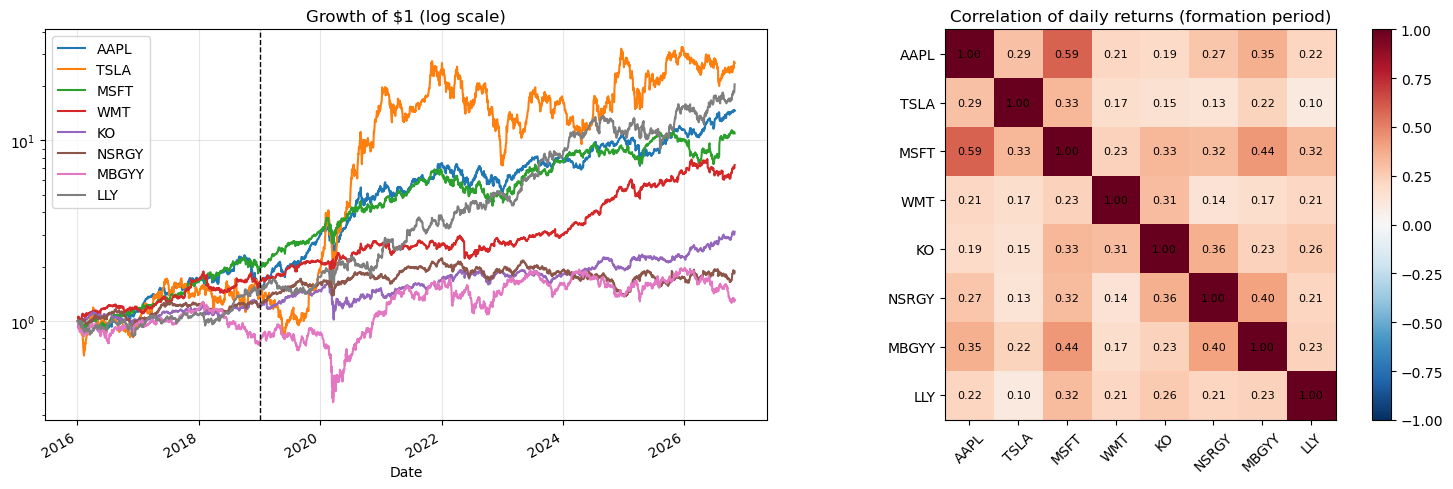

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
(closes / closes.iloc[0]).plot(ax=ax[0], logy=True, title="Growth of $1 (log scale)")
ax[0].axvline(pd.Timestamp(TEST_START), color="black", ls="--", lw=1)
ax[0].grid(alpha=.3)

corr = returns.loc[:FORMATION_END].corr()
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr)), corr.columns, rotation=45)
ax[1].set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("Correlation of daily returns (formation period)")
fig.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

The time-series plots reveal that several stocks (LLY, TSLA, AAPL, and MSFT) generated exceptionally high returns over the whole period. This suggests that the selected stocks may introduce a degree of selection bias and may not be fully representative of the broader market. 
From a fundamental perspective, the portfolio consists of three major technology companies, three large food and beverage companies, one retailer, and one pharmaceutical company. This composition indicates a relatively concentrated sector allocation, particularly towards technology, a sector that has experienced substantial growth over the past decade. Consequently, the observed portfolio performance may be disproportionately influenced by the strong performance of a limited number of companies and sectors rather than reflecting broader market trends.

Therefore, when evaluating a strategy against benchmark it is necessary to keep in mind set upon which it were evaluated.

#### Helper functions

The purpose of this section is to write functions that will be useful later.

In [9]:
PCT_ROWS = ["Total return", "Annualised return", "CAGR", "Annualised volatility", "Maximum drawdown"]

def show(table): # formats a summary table (percentages and ratios)
    out = table.astype(object).copy()
    for row in table.index:
        fmt = "{:.2%}" if row in PCT_ROWS or "%" in row else "{:.2f}"
        out.loc[row] = [fmt.format(v) for v in table.loc[row]]
    return out

def compare(portfolios):
    return pd.DataFrame({name: summary(p) for name, p in portfolios.items()})

def plot_equity(portfolios, title):
    fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    for name, p in portfolios.items():
        v = p.portfolio_value
        ax[0].plot(v / v.iloc[0], label=name)
        ax[1].plot(v / v.cummax() - 1, label=name)
    ax[0].set_title(title); ax[0].set_ylabel("Growth of $1"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].set_ylabel("Drawdown"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

def exposure(p): # gross exposure = sum of |position values| / portfolio value
    values = pd.DataFrame({s.name: s.history.set_index("date")["price"] * s.history.set_index("date")["num_of_shares"]
                           for s in p.instruments if s.name != CASH})
    return values.abs().sum(axis=1) / p.portfolio_value

def trading_stats(bt):
    return pd.Series({"Trades": len(bt.trades), "Total costs ($)": bt.trades["cost"].sum(),
                      "Avg. gross exposure": exposure(bt.portfolio).mean()})

portfolios, backtests = {}, {}

### First benchmark: equal-weight buy & hold

The underlying idea is to invest an equal amount in each of the eight selected stocks at the beginning of the observation period and hold these positions throughout the entire period, without rebalancing. This buy-and-hold portfolio serves as a passive benchmark against which all active investment strategies are evaluated.

The purpose of this benchmark is not necessarily to outperform the active strategies, but rather to capture the overall evolution of the selected eight-stock universe over the observed period. In this way, it provides a reference point for assessing whether active portfolio management adds value beyond simply maintaining an initial equal-weight allocation and benefiting from subsequent market movements.

In [10]:
benchmark_bt = Backtest(data, buy_and_hold, INITIAL_CAPITAL, TRANSACTION_COST)
portfolios["Buy & hold (EW)"] = benchmark_bt.run(start_date=TEST_START)
backtests["Buy & hold (EW)"] = benchmark_bt
show(compare(portfolios))

,Buy & hold (EW)
Total return,619.01%
Annualised return,28.74%
CAGR,28.67%
Annualised volatility,28.66%
Sharpe ratio,1.03
Sortino ratio,1.49
Maximum drawdown,42.96%
Calmar ratio,0.67


As expected this strategy has showed high returns.

## Mean reversion strategy

Short-term price moves away from a recent average tend to partly reverse. For each stock we compute the z-score of today's close against the last `lookback` closes (a Bollinger-band signal):

$$z_t = \frac{P_t - \text{mean}(P_{t-L+1..t})}{\text{std}(P_{t-L+1..t})}$$

- **Enter long** when $z < -\text{entry\_z}$ (price unusually low), **exit** when $z > -\text{exit\_z}$.
- Optionally **enter short** when $z > \text{entry\_z}$, exit when $z < \text{exit\_z}$.
- Each stock gets an equal slice (1/8) of current equity, so the strategy holds cash when there are no signals.

In [11]:
def mean_reversion(date, data, positions, cash, lookback=20, entry_z=2.0, exit_z=0.5, allow_short=False):
    closes = pd.DataFrame({name: df["Close"].iloc[-lookback:] for name, df in data.items()})
    if len(closes) < lookback: # not enough data yet
        return None
    last = closes.iloc[-1]
    z = (last - closes.mean()) / closes.std()

    equity = cash + sum(positions[name] * last[name] for name in positions)
    slot = equity / len(data) # equal money per security

    target = {}
    for name in data:
        if positions[name] == 0:
            if z[name] < -entry_z:
                target[name] = np.floor(slot / last[name])
            elif allow_short and z[name] > entry_z:
                target[name] = -np.floor(slot / last[name])
        elif positions[name] > 0 and z[name] > -exit_z:
            target[name] = 0
        elif positions[name] < 0 and z[name] < exit_z:
            target[name] = 0
    return target

In [12]:
mr_bt = Backtest(data, mean_reversion, INITIAL_CAPITAL, TRANSACTION_COST)
portfolios["Mean reversion (long)"] = mr_bt.run(start_date=TEST_START, lookback=20, entry_z=2.0, exit_z=0.5)
backtests["Mean reversion (long)"] = mr_bt

mr_ls_bt = Backtest(data, mean_reversion, INITIAL_CAPITAL, TRANSACTION_COST)
portfolios["Mean reversion (long/short)"] = mr_ls_bt.run(start_date=TEST_START, lookback=20, entry_z=2.0, exit_z=0.5, allow_short=True)
backtests["Mean reversion (long/short)"] = mr_ls_bt

show(compare(portfolios))

,Buy & hold (EW),Mean reversion (long),Mean reversion (long/short)
Total return,619.01%,22.97%,-53.42%
Annualised return,28.74%,2.68%,-9.32%
CAGR,28.67%,2.68%,-9.30%
Annualised volatility,28.66%,9.09%,12.24%
Sharpe ratio,1.03,0.34,-0.74
Sortino ratio,1.49,0.48,-1.02
Maximum drawdown,42.96%,19.32%,57.95%
Calmar ratio,0.67,0.14,-0.16


In [13]:
pd.DataFrame({name: trading_stats(bt) for name, bt in backtests.items()}).round(2)

,Buy & hold (EW),Mean reversion (long),Mean reversion (long/short)
Trades,8.00,538.00,1182.00
Total costs ($),97.54,7398.78,9286.82
Avg. gross exposure,0.99,0.15,0.44


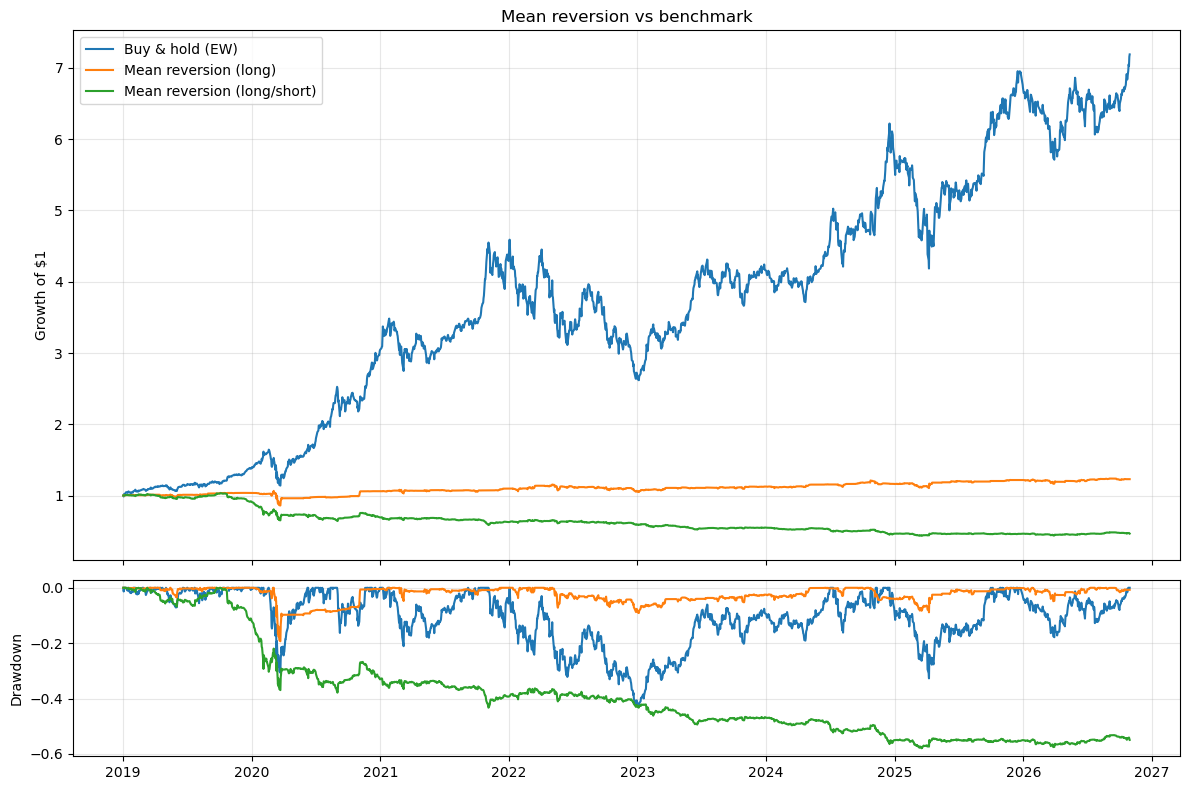

,date,name,quantity,price,value,cost
528,2026-08-21,WMT,148.0,103.690002,15346.120361,15.346120
529,2026-09-04,WMT,-148.0,108.199997,-16013.599548,16.013600
530,2026-09-21,MBGYY,1227.0,12.580000,15435.659906,15.435660
531,2026-10-01,WMT,147.0,104.379997,15343.859596,15.343860
532,2026-10-01,KO,177.0,86.230003,15262.710594,15.262711
533,2026-10-02,NSRGY,170.0,90.459999,15378.199844,15.378200
534,2026-10-07,WMT,-147.0,107.540001,-15808.380135,15.808380
535,2026-10-09,KO,-177.0,87.599998,-15505.199730,15.505200
536,2026-10-09,NSRGY,-170.0,91.360001,-15531.200104,15.531200
537,2026-10-19,MBGYY,-1227.0,11.280000,-13840.559672,13.840560


In [14]:
plot_equity({k: portfolios[k] for k in ["Buy & hold (EW)", "Mean reversion (long)", "Mean reversion (long/short)"]}, "Mean reversion vs benchmark")
mr_bt.trades.tail(10)

### Parameter sensitivity

A strategy that only works for one exact parameter choice is probably overfitted. Below is the Sharpe ratio over a small grid. The point is to see whether the result is **stable**, not to pick the best cell (picking the best cell on the test period would be look-ahead bias).

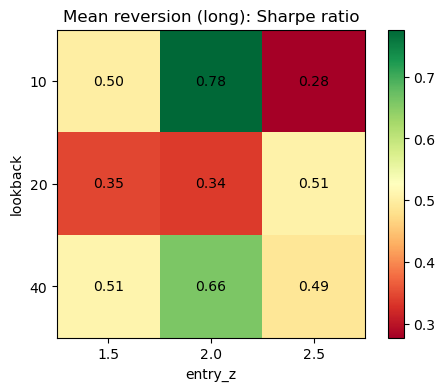

In [15]:
grid_bt = Backtest(data, mean_reversion, INITIAL_CAPITAL, TRANSACTION_COST)
grid = {}
for lookback in [10, 20, 40]:
    for entry_z in [1.5, 2.0, 2.5]:
        grid[(lookback, entry_z)] = grid_bt.run(start_date=TEST_START, lookback=lookback, entry_z=entry_z).sharpe_ratio()
sensitivity = pd.Series(grid).unstack()
sensitivity.index.name, sensitivity.columns.name = "lookback", "entry_z"

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(sensitivity, cmap="RdYlGn")
ax.set_xticks(range(len(sensitivity.columns)), sensitivity.columns); ax.set_xlabel("entry_z")
ax.set_yticks(range(len(sensitivity.index)), sensitivity.index); ax.set_ylabel("lookback")
for i in range(sensitivity.shape[0]):
    for j in range(sensitivity.shape[1]):
        ax.text(j, i, f"{sensitivity.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Mean reversion (long): Sharpe ratio"); fig.colorbar(im); plt.show()

### Strategy 2: Pairs trading

If two stocks are *cointegrated*, a combination of their log-prices (the spread) is stationary, so when it drifts far from its mean it tends to come back. We trade the spread instead of the stocks.

**Step 1: choose pairs on the formation period only.** For all 28 pairs we run the Engle–Granger cointegration test on 2016–2018 log-prices and greedily pick the pairs with the lowest p-values, without reusing a stock (so each stock belongs to at most one pair).

In [16]:
formation = np.log(closes.loc[:FORMATION_END])
rows = []
for a, b in itertools.combinations(closes.columns, 2):
    p_ab = coint(formation[a], formation[b])[1] # Engle-Granger is not symmetric, test both directions
    p_ba = coint(formation[b], formation[a])[1]
    rows.append((a, b, p_ab) if p_ab <= p_ba else (b, a, p_ba))
coint_results = pd.DataFrame(rows, columns=["A", "B", "p-value"]).sort_values("p-value").reset_index(drop=True)

N_PAIRS = 3
PAIRS, used = [], set()
for _, row in coint_results.iterrows():
    if row["A"] not in used and row["B"] not in used:
        PAIRS.append((row["A"], row["B"]))
        used |= {row["A"], row["B"]}
    if len(PAIRS) == N_PAIRS:
        break

print("Selected pairs:", PAIRS)
if (coint_results.set_index(["A", "B"]).loc[PAIRS, "p-value"] > 0.05).any():
    print("Note: some selected pairs are NOT cointegrated at 5%; with only 8 stocks from different sectors this is expected.")
coint_results.head(10)

Selected pairs: [('TSLA', 'NSRGY'), ('KO', 'LLY'), ('WMT', 'MSFT')]
Note: some selected pairs are NOT cointegrated at 5%; with only 8 stocks from different sectors this is expected.


,A,B,p-value
0,TSLA,NSRGY,0.017652
1,KO,LLY,0.060325
2,WMT,MSFT,0.067031
3,TSLA,KO,0.112910
4,TSLA,WMT,0.143871
5,NSRGY,WMT,0.184834
6,KO,WMT,0.189779
7,TSLA,AAPL,0.201673
8,WMT,LLY,0.249042
9,NSRGY,KO,0.254107


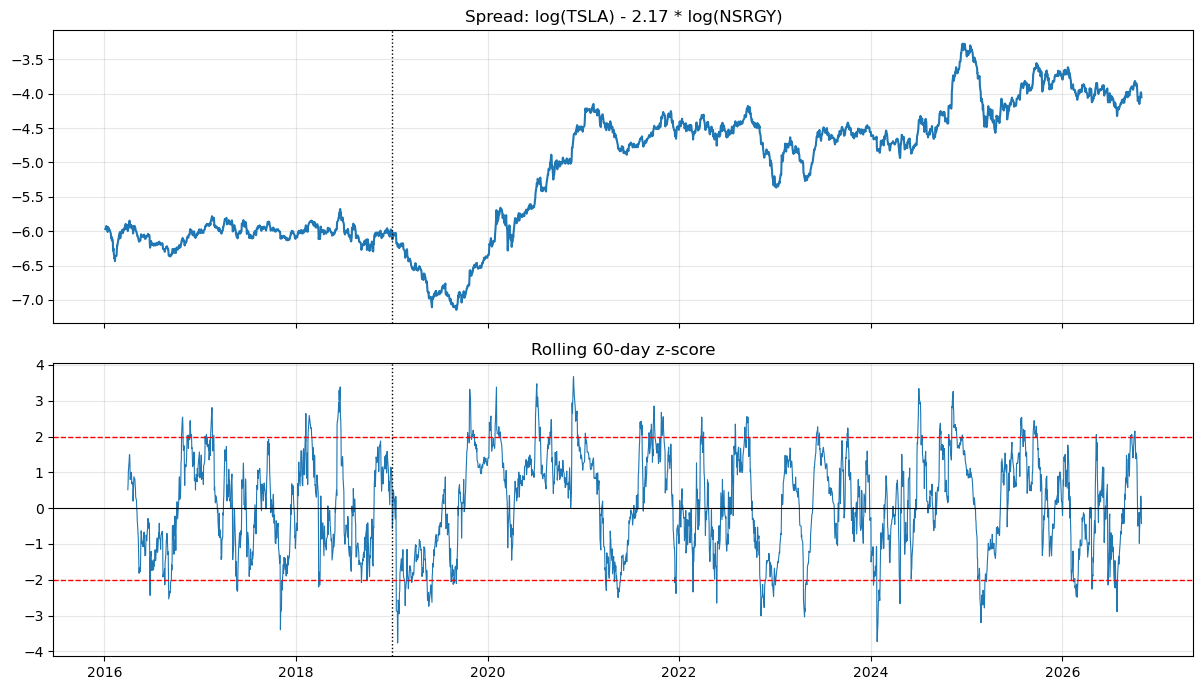

In [17]:
# spread of the best pair, hedge ratio estimated on the formation period
a, b = PAIRS[0]
beta = np.polyfit(formation[b], formation[a], 1)[0]
spread = np.log(closes[a]) - beta * np.log(closes[b])
z = (spread - spread.rolling(60).mean()) / spread.rolling(60).std()

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(spread); ax[0].set_title(f"Spread: log({a}) - {beta:.2f} * log({b})"); ax[0].grid(alpha=.3)
ax[1].plot(z, lw=.8); ax[1].set_title("Rolling 60-day z-score")
for level in [-2, 2]: ax[1].axhline(level, color="red", ls="--", lw=1)
ax[1].axhline(0, color="black", lw=.8)
for axis in ax: axis.axvline(pd.Timestamp(TEST_START), color="black", ls=":", lw=1)
ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

**Step 2: trading rule.** Every day, for each pair (A, B):
1. Estimate the hedge ratio β by regressing log(A) on log(B) over the last `lookback` days (rolling, so it adapts and never looks ahead).
2. Spread = log(A) − β·log(B); compute its z-score over the same window.
3. **z > entry_z** → spread too high → short A, long B. **z < −entry_z** → long A, short B. Money is split so that value(B) = β · value(A) (roughly market-neutral).
4. **Exit** when |z| < exit_z (spread reverted) or |z| > stop_z (stop-loss: the relationship may have broken).

In [18]:
def pairs_trading(date, data, positions, cash, pairs, lookback=60, entry_z=2.0, exit_z=0.5, stop_z=4.0):
    if len(data[pairs[0][0]]) < lookback: # not enough data yet
        return None
    last = {name: df["Close"].iloc[-1] for name, df in data.items()}
    equity = cash + sum(positions[name] * last[name] for name in positions)
    slot = equity / len(pairs) # equal money per pair

    target = {}
    for a, b in pairs:
        y = np.log(data[a]["Close"].iloc[-lookback:])
        x = np.log(data[b]["Close"].iloc[-lookback:])
        beta = np.polyfit(x, y, 1)[0] # hedge ratio
        spread = y - beta * x
        z = (spread.iloc[-1] - spread.mean()) / spread.std()

        if positions[a] == 0 and positions[b] == 0:
            if beta <= 0: # negative hedge ratio makes no sense for this strategy
                continue
            n_a = np.floor(slot / (1 + beta) / last[a])
            n_b = np.floor(slot * beta / (1 + beta) / last[b])
            if n_a == 0 or n_b == 0:
                continue
            if z > entry_z:    # spread too high: short A, long B
                target[a], target[b] = -n_a, n_b
            elif z < -entry_z: # spread too low: long A, short B
                target[a], target[b] = n_a, -n_b
        elif abs(z) < exit_z or abs(z) > stop_z: # reverted or stop-loss
            target[a], target[b] = 0, 0
    return target

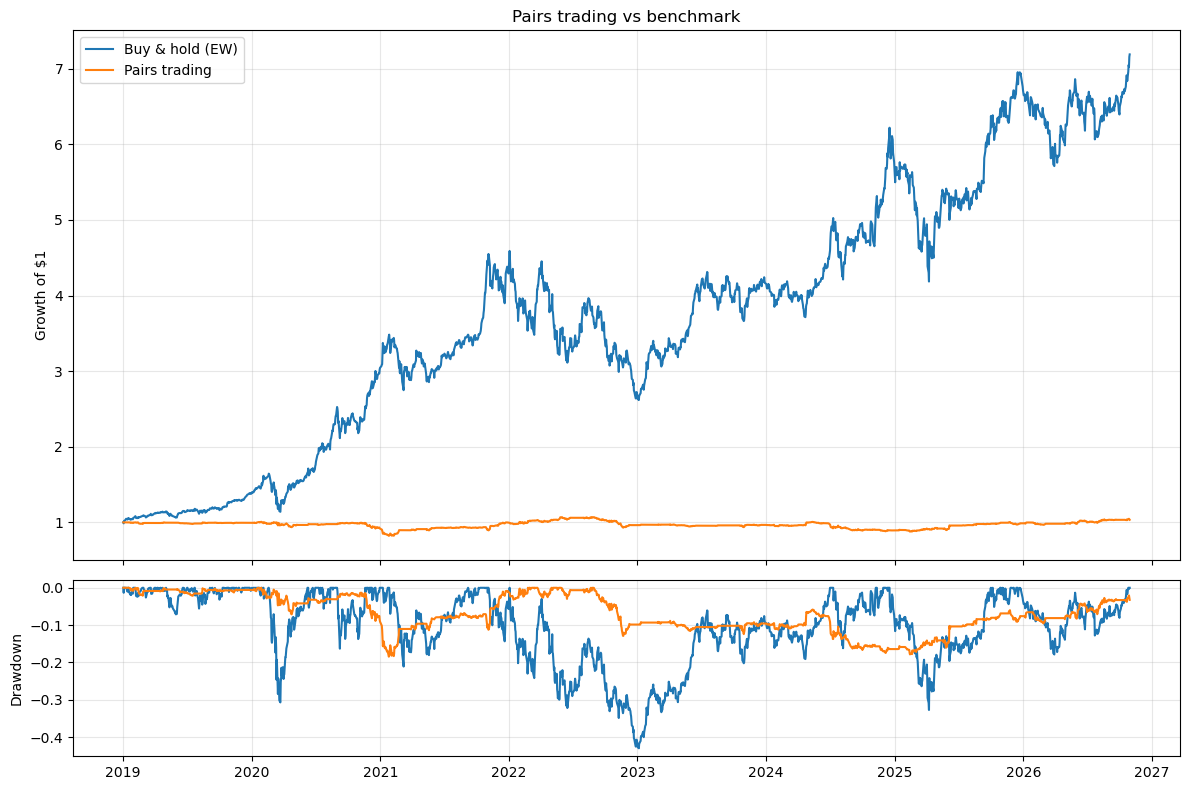

,date,name,quantity,price,value,cost
400,2026-08-20,TSLA,-108.0,346.200012,-37389.601318,37.389601
401,2026-08-20,NSRGY,3.0,98.879997,296.639992,0.296640
402,2026-09-22,KO,304.0,87.599998,26630.399536,26.630400
403,2026-09-22,LLY,-5.0,1146.150024,-5730.750122,5.730750
404,2026-10-19,KO,-286.0,92.559998,-26472.159302,26.472159
405,2026-10-19,LLY,5.0,1243.390015,6216.950073,6.216950
406,2026-10-23,WMT,-220.0,121.580002,-26747.600403,26.747600
407,2026-10-23,MSFT,14.0,517.750000,7248.500000,7.248500
408,2026-10-28,KO,286.0,90.839996,25980.238953,25.980239
409,2026-10-28,LLY,-5.0,1268.550049,-6342.750244,6.342750


In [19]:
pairs_bt = Backtest(data, pairs_trading, INITIAL_CAPITAL, TRANSACTION_COST)
portfolios["Pairs trading"] = pairs_bt.run(start_date=TEST_START, pairs=PAIRS, lookback=60, entry_z=2.0, exit_z=0.5, stop_z=4.0)
backtests["Pairs trading"] = pairs_bt

plot_equity({k: portfolios[k] for k in ["Buy & hold (EW)", "Pairs trading"]}, "Pairs trading vs benchmark")
pairs_bt.trades.tail(10)

### Second benchmark: minimum-variance portfolio

Using `Portfolio.MeanVarianceOptimisation()` on the **formation period** to get long-only minimum-variance weights, then buying and holding them through the test period.

In [20]:
formation_portfolio = Backtest(data, buy_and_hold, INITIAL_CAPITAL, TRANSACTION_COST).run(end_date=FORMATION_END)
mvo_weights = formation_portfolio.MeanVarianceOptimisation()
print(mvo_weights.round(3).sort_values(ascending=False).to_string())

mvo_bt = Backtest(data, buy_and_hold, INITIAL_CAPITAL, TRANSACTION_COST)
portfolios["Min. variance (B&H)"] = mvo_bt.run(start_date=TEST_START, weights=mvo_weights.to_dict())
backtests["Min. variance (B&H)"] = mvo_bt

KO       0.423
NSRGY    0.276
WMT      0.115
LLY      0.106
AAPL     0.061
MBGYY    0.018
MSFT     0.000
TSLA     0.000


### Comparison

In [21]:
show(compare(portfolios))

,Buy & hold (EW),Mean reversion (long),Mean reversion (long/short),Pairs trading,Min. variance (B&H)
Total return,619.01%,22.97%,-53.42%,3.37%,303.98%
Annualised return,28.74%,2.68%,-9.32%,0.43%,19.58%
CAGR,28.67%,2.68%,-9.30%,0.42%,19.53%
Annualised volatility,28.66%,9.09%,12.24%,7.39%,16.48%
Sharpe ratio,1.03,0.34,-0.74,0.09,1.17
Sortino ratio,1.49,0.48,-1.02,0.14,1.72
Maximum drawdown,42.96%,19.32%,57.95%,18.45%,24.65%
Calmar ratio,0.67,0.14,-0.16,0.02,0.79


In [22]:
pd.DataFrame({name: trading_stats(bt) for name, bt in backtests.items()}).round(2)

,Buy & hold (EW),Mean reversion (long),Mean reversion (long/short),Pairs trading,Min. variance (B&H)
Trades,8.00,538.00,1182.00,410.00,6.00
Total costs ($),97.54,7398.78,9286.82,6653.37,98.83
Avg. gross exposure,0.99,0.15,0.44,0.30,0.99


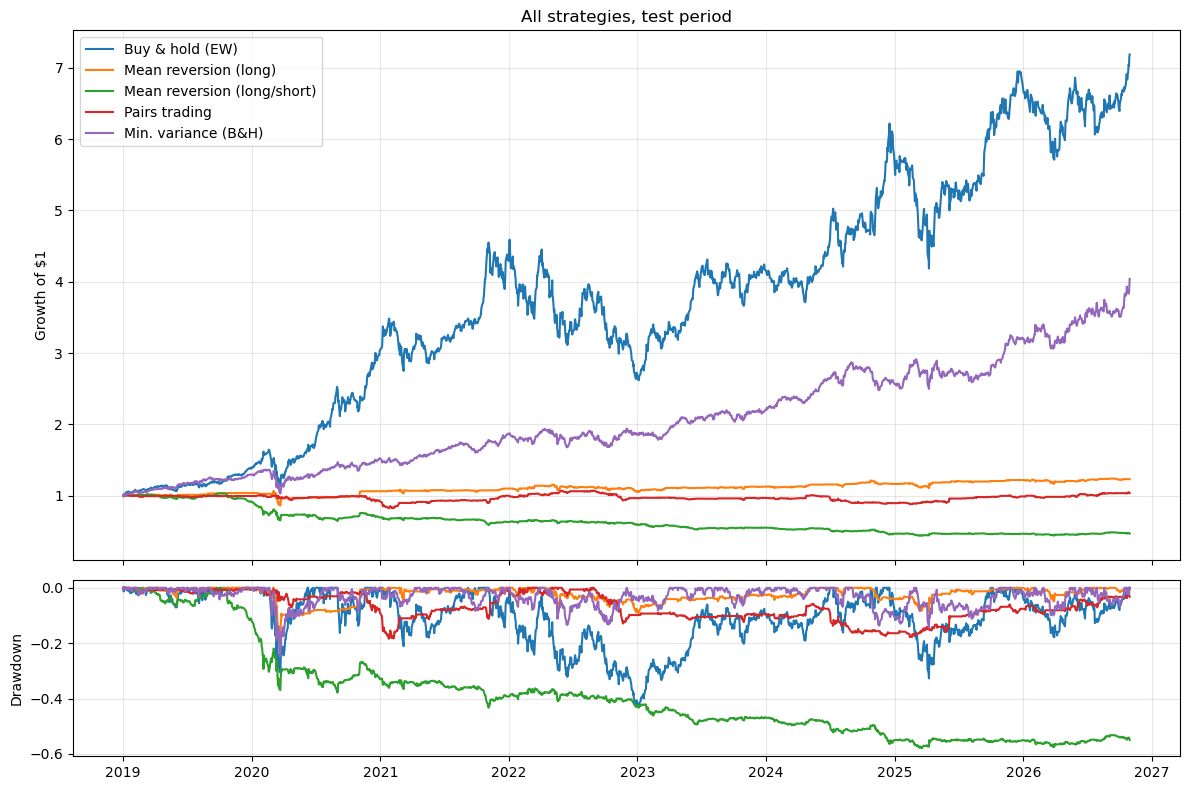

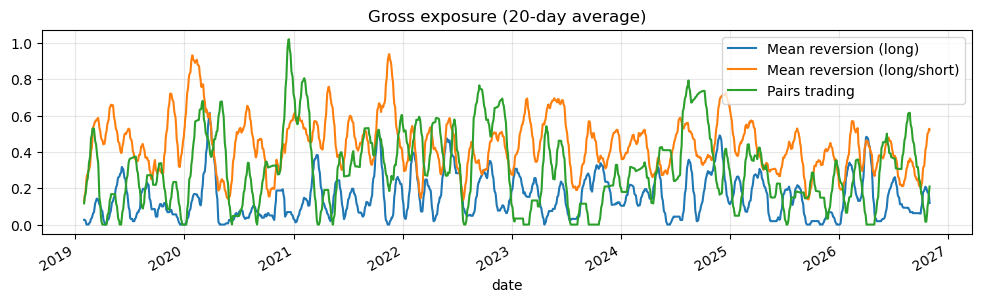

In [23]:
plot_equity(portfolios, "All strategies, test period")

fig, ax = plt.subplots(figsize=(12, 3))
for name in ["Mean reversion (long)", "Mean reversion (long/short)", "Pairs trading"]:
    exposure(portfolios[name]).rolling(20).mean().plot(ax=ax, label=name)
ax.set_title("Gross exposure (20-day average)"); ax.legend(); ax.grid(alpha=.3); plt.show()

### Risk analysis

All VaR / ES numbers are 1-day, shown as a percent of the current portfolio value. Significance level α = 5% and 1%. The Student-t Monte Carlo (4 degrees of freedom) shows how much the normal assumption understates tail risk.

In [25]:
risk_table = {}
for name, p in portfolios.items():
    rm, value = RiskMetrics(p), p.value()
    row = {}
    for alpha in [0.05, 0.01]:
        a = f"{alpha:.0%}"
        row[f"Historic VaR {a}"] = rm.historicVaR(alpha) / value
        row[f"Parametric VaR {a}"] = rm.parametricVaR(alpha) / value
        row[f"Monte Carlo VaR {a} (normal)"] = rm.MonteCarloVaR(alpha, 100_000) / value
        row[f"Monte Carlo VaR {a} (Student t)"] = rm.MonteCarloVaR(alpha, 100_000, "student", 4) / value
        row[f"Historic ES {a}"] = rm.historicES(alpha) / value
        row[f"Parametric ES {a}"] = rm.parametricES(alpha) / value
        row[f"Monte Carlo ES {a} (normal)"] = rm.MonteCarloES(alpha, 100_000) / value
    risk_table[name] = row
risk_table = pd.DataFrame(risk_table)
show(risk_table)

,Buy & hold (EW),Mean reversion (long),Mean reversion (long/short),Pairs trading,Min. variance (B&H)
Historic VaR 5%,2.85%,0.55%,1.06%,0.65%,1.43%
Parametric VaR 5%,2.97%,0.94%,1.27%,0.77%,1.71%
Monte Carlo VaR 5% (normal),2.84%,0.93%,1.30%,0.76%,1.64%
Monte Carlo VaR 5% (Student t),2.61%,0.85%,1.21%,0.70%,1.47%
Historic ES 5%,4.14%,1.22%,1.77%,1.11%,2.31%
Parametric ES 5%,3.72%,1.18%,1.59%,0.96%,2.14%
Monte Carlo ES 5% (normal),3.61%,1.17%,1.64%,0.96%,2.06%
Historic VaR 1%,4.86%,1.41%,1.97%,1.45%,2.55%
Parametric VaR 1%,4.20%,1.33%,1.79%,1.08%,2.41%
Monte Carlo VaR 1% (normal),4.06%,1.32%,1.84%,1.07%,2.32%


#### Risk attribution and concentration (passive portfolios, last day)

Percentage risk contribution shows which stocks actually drive portfolio volatility; it is often very different from the money weights.

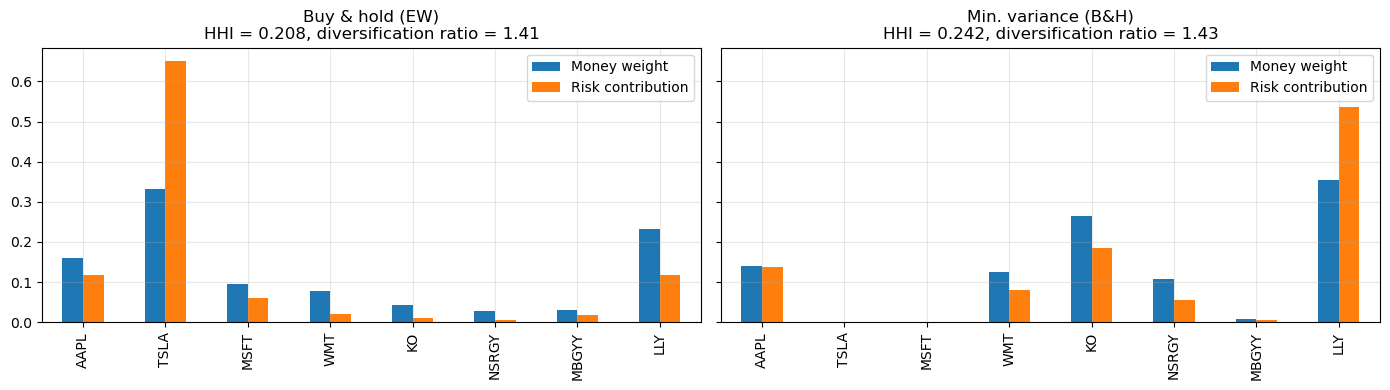

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for axis, name in zip(ax, ["Buy & hold (EW)", "Min. variance (B&H)"]):
    p, rm = portfolios[name], RiskMetrics(portfolios[name])
    weights = pd.Series(p.position_weights()).drop(CASH)
    contribution = pd.Series(rm.pct_risk_contribution()).drop(CASH)[weights.index]
    pd.DataFrame({"Money weight": weights, "Risk contribution": contribution}).plot.bar(ax=axis)
    axis.set_title(f"{name}\nHHI = {p.herfindahl_index():.3f}, diversification ratio = {p.diversification_ratio():.2f}")
    axis.grid(alpha=.3)
plt.tight_layout(); plt.show()

#### Stress tests

- **Hypothetical:** a one-day tech sell-off applied to the current positions.
- **Historical:** the COVID crash (19 Feb – 23 Mar 2020) and the 2022 rate-hike bear market replayed on the current positions.

Active strategies that are flat on the last day show 0%. That is correct (they hold only cash), but it also means a stress test on the final day says little about them.

In [27]:
TECH_SELLOFF = {"AAPL": -0.15, "MSFT": -0.12, "TSLA": -0.25, "LLY": -0.05, "WMT": -0.03, "KO": -0.02, "NSRGY": -0.02, "MBGYY": -0.08}
SCENARIOS = {"COVID crash 2020": ("2020-02-19", "2020-03-23"), "Rate hikes 2022": ("2022-01-03", "2022-10-12")}

stress = {}
for name, p in portfolios.items():
    rm, value = RiskMetrics(p), p.value()
    row = {"Tech sell-off (hypothetical)": rm.hypothetical_stress_test(TECH_SELLOFF).value() / value - 1}
    for scenario, (start, end) in SCENARIOS.items():
        row[scenario] = rm.historical_stress_test(start, end).value() / value - 1
    stress[name] = row
stress = pd.DataFrame(stress)
show(stress.rename(index=lambda r: r + " %"))

,Buy & hold (EW),Mean reversion (long),Mean reversion (long/short),Pairs trading,Min. variance (B&H)
Tech sell-off (hypothetical) %,-13.60%,0.00%,4.29%,-0.06%,-5.04%
COVID crash 2020 %,-32.19%,0.00%,10.71%,-1.29%,-21.83%
Rate hikes 2022 %,-19.49%,0.00%,7.10%,-0.10%,-0.90%


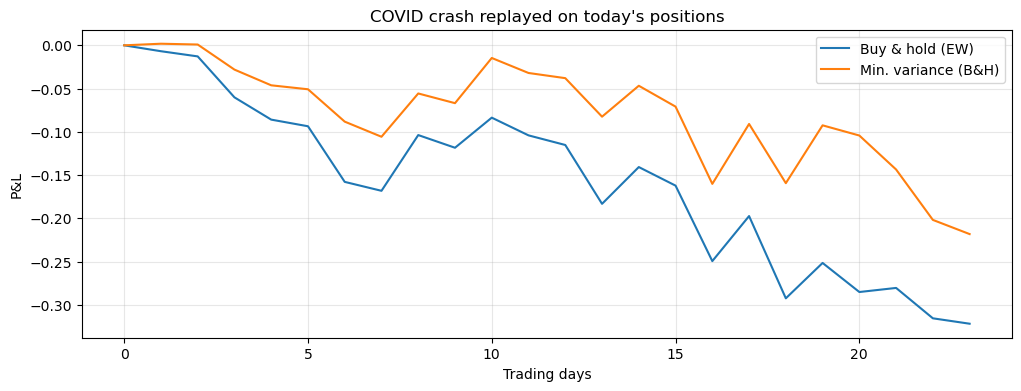

In [28]:
start, end = SCENARIOS["COVID crash 2020"]
fig, ax = plt.subplots(figsize=(12, 4))
for name in ["Buy & hold (EW)", "Min. variance (B&H)"]:
    path = RiskMetrics(portfolios[name]).historical_stress_test(start, end).portfolio_value
    ax.plot(range(len(path)), path / path.iloc[0] - 1, label=name)
ax.set_title("COVID crash replayed on today's positions"); ax.set_xlabel("Trading days"); ax.set_ylabel("P&L")
ax.legend(); ax.grid(alpha=.3); plt.show()

### Conclusions and limitations

**How to read the results**
- Compare each strategy with *both* benchmarks on **risk-adjusted** metrics (Sharpe, Sortino, Calmar), not only total return. Active strategies hold cash much of the time (see gross exposure), so a lower return with much lower volatility and drawdown can still be a good result.
- The sensitivity grid shows whether mean reversion is robust or depends on one lucky parameter set.
- In the pairs section, check the cointegration p-values: pairs that weren't cointegrated in the formation period have no statistical reason to revert.

**Limitations (things a real desk would add)**
- *Selection bias:* the eight stocks were chosen in hindsight, and several (LLY, TSLA, AAPL, MSFT) were huge winners, which favours buy & hold.
- *Costs:* a flat 0.1% cost; no bid–ask spread modelling, short-borrow fees or margin interest. The ADRs (NSRGY, MBGYY) are OTC and less liquid than the underlying shares.
- *Risk-free rate* is assumed to be 0 in Sharpe/Sortino; idle cash earns nothing.
- *Parametric VaR* assumes normal returns; the Student-t Monte Carlo and historic ES show how much fatter the real tails are.
- *Rolling hedge ratio:* a 60-day β can be unstable for weakly related pairs, which sometimes produces nearly one-legged (unhedged) trades.
- *Single test period:* a walk-forward analysis (re-estimating pairs every year) would give a more reliable estimate.